# Can an FFT / NUFFT recover the true trade-frequency parameters?

**This is a methods-validation notebook on pure simulation.** Nothing here touches
real data, so the pre-registration and point-in-time gates do not apply — this is the
"calibrate on simulated data with a known answer" step that `hft_clock.py` keeps
referring to. The question is narrow and mechanical:

> If I *plant* a trading schedule with a known period `P`, modulation depth `A` and
> phase `φ` into a simulated event stream, does the spectral estimator hand those
> three numbers back — and what breaks when the timestamps stop being a clean grid
> and start looking like a real Hyperliquid × Binance feed?

Three estimators, each tested against the sampling geometry it is meant for:

| Estimator | What it is | Its native geometry |
|---|---|---|
| **Ordinary FFT** | `np.fft.rfft` of binned counts | a uniform grid (every 5 ms) |
| **FFT-after-resampling** | bin irregular events to 5 ms, then FFT | the naive thing to do to irregular data |
| **NUDFT / "NUFFT"** | the exact sum `Σ w exp(-2πi f t)` (`hft_clock.ndft_power`) | genuinely irregular arrivals |

A **NUFFT is a fast algorithm for the NUDFT, not a different statistic** — at these sizes
the exact sum runs in seconds, so we compute it exactly and get the ground-truth answer a
`finufft` call would reproduce faster. (`finufft` is not installed here; it would change
the runtime, not the numbers.)

### What this notebook learns (revised 2026-10-21, see the Summary below)
1. **Scan finely enough.** A peak in the NUDFT is only ~1/span wide (here 0.00056 Hz). A scan grid coarser than that
   steps over the true peak and hands back noise. The first version of this notebook did exactly that, and two of its
   headline findings were artefacts of it.
2. **Under burstiness, scan-and-select fools every per-period test.** Clustered arrivals throw
   peaks that clear the multiplicity line *and* pass local-contrast *and* pass phase-stability —
   because picking the loudest peak is the bias. Name the candidate in advance; read effect size.
3. **The feed comb is real but, in this simulation, much weaker than the schedule** (~40× lower power at A = 0.4). It
   would only win for weak schedules, so excluding it is still good practice; it is not what decides success here.

### ASSUMPTIONS (flagged, not silently chosen) — see KNOBS and the final list
The one real modelling choice is *what an irregular HL × Binance timeline looks like*. It
lives in `sim_hl_binance`; every assumption is marked `# ASSUMPTION:`.

## Summary (rerun 2026-10-21, after a correction)

**What was wrong in v1 (2026-10-15).** The NUDFT scan used a fixed number of frequencies (4,000 over 0.2–20 Hz in
Exp 1–2; 1,500 per band in Exp 3). That made the step 2.5–18× wider than a peak, so the scan could step over the true
peak. Two v1 findings came from this, and both are **retracted**:
* *"The naive NUDFT locks onto the feed comb (50 ms)."* The 50 ms comb line sits at 20 Hz, the grid's end point, so the
  coarse grid landed exactly on it while missing the 1 s peak. With a correct grid the naive global peak **is** the
  1 s schedule (z = 21,727 vs ~550 for the 100 ms and 50 ms comb lines).
* *"The raw-event NUDFT stumbles at 80 ms and 250 ms because comb power leaks."* It stumbled because the grid stepped
  over the peak (the picked peaks had z = 20 and 34, against ~7,600 and ~17,900 at the truth).

The fix: scan step = 1/(2·span) (`SCAN_OVERSAMPLE`), computed exactly with a faster recurrence that agrees with
`hc.ndft_power` to ~1e-10.

**Results now**

| | FFT, 5 ms counts | NUDFT, raw times |
|---|---|---|
| Exp 1, clean: P / A / φ error | 0% / 0.0003 / 0.000 rad | 0.0003% / 0.0003 / 0.016 rad |
| Exp 2, HL × Binance: naive global peak | 1 s schedule | 1 s schedule |
| Exp 3, sweep 80 ms–3 s: period error | 0% everywhere | ≤ 0.001% everywhere |
| Exp 3: phase error at the named period | 0.02–0.59 rad, the same for both | same |

**Read with care**
* Every swept period sits **exactly on an FFT bin** (span/P is a whole number; column `on_fft_bin`). Real periods won't,
  and an unpadded FFT loses power between bins. The FFT's 0% period error here is partly that luck.
* The phase errors (0.02–0.59 rad) behave like a fixed ~7–15 ms lag, not noise: the simulated bursts' children arrive
  after their parents. The estimators return the phase of the *observed* stream, which the clustering has shifted.
* Exp 4 (the null) is unchanged; it used `hc.scan_band`, whose grid was already fine enough.
* The simulation's feed model is now contradicted by the data (see Assumptions at the end).

## KNOBS — everything tunable lives here

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hft_clock as hc  # reuse the audited NUDFT / Rayleigh / scan machinery

# ---- ground truth planted into the simulation -----------------------------
TRUE_PERIOD_S = 1.0        # the scheduled trade interval we try to recover (s)
TRUE_MOD_A    = 0.40       # modulation depth of the schedule, in [0, 1]
TRUE_PHASE    = 1.10       # phase of the schedule (radians), where in the cycle it fires
BASE_RATE_HZ  = 200.0      # mean event rate (events/second) across the whole stream
SPAN_S        = 1800.0     # length of the simulated record (s). resolution = 1/SPAN_S Hz

# ---- the uniform observation clock ----------------------------------------
GRID_DT_S     = 0.005      # 5 ms grid for the ordinary-FFT experiment. Nyquist = 100 Hz

# ---- the irregular HL x Binance feed model (ASSUMPTIONS, all here) ---------
BIN_CADENCE_S = 0.100      # ASSUMPTION: Binance depth-diff push cadence (100 ms grid)
BIN_SHARE     = 0.55       # ASSUMPTION: fraction of events that come from the Binance feed
LATENCY_MS    = 0.30       # ASSUMPTION: timestamp jitter / latency, ms (one-sided exp scale)
BURST_CHILDREN = 2.5       # ASSUMPTION: mean extra events each arrival triggers (Hawkes-ish)
BURST_DECAY_S  = 0.020     # ASSUMPTION: cluster decay time for triggered events (s)

# ---- estimator / scan settings --------------------------------------------
SCAN_PLO_S    = 0.05       # shortest period to scan (s)
SCAN_PHI_S    = 5.0        # longest period to scan (s)
SCAN_OVERSAMPLE = 2        # NUDFT scan step = 1/(SCAN_OVERSAMPLE*SPAN_S). A peak's main lobe is ~1/SPAN_S wide, so this
                           # puts >= 2 points on every lobe. (v1 used a fixed 4000 / 1500 points and stepped over peaks.)
COMB_TOL      = 0.03       # exclude +/- this fractional band around each feed-comb harmonic
SWEEP_PERIODS = np.array([0.08, 0.15, 0.25, 0.5, 1.0, 2.0, 3.0])  # recovery-vs-period sweep
SEED          = 7

rng_master = np.random.default_rng(SEED)
TWO_PI = 2.0 * np.pi

## Generative model and the shared recovery machinery

**The planted signal.** An inhomogeneous Poisson process with intensity
$\lambda(t) = \lambda_0\,\bigl(1 + A\cos(2\pi t/P + \varphi)\bigr)$. The schedule lives in
the periodic factor; `A` is how strongly activity concentrates at one phase of the cycle.
For this process the Rayleigh resultant at the true period is exactly $R = A/2$, so the
recoverable amplitude is $\hat A = 2R$ — that is the ground truth the estimators must return.

**One recovery helper, used identically for every estimator** so the comparison is fair:
project the series onto $\cos/\sin$ at a frequency and read off amplitude and phase. On a
point process the weights are 1; on the 5 ms grid the weights are the bin counts.

In [2]:
def sim_periodic_poisson(period, mod_a, phase, base_rate, span, rng):
    """Inhomogeneous-Poisson event times carrying a known schedule. Thinning method.
    lambda(t) = base_rate * (1 + mod_a*cos(2*pi*t/period + phase)), mod_a in [0,1].
    The returned times are themselves irregular (Poisson): the grid experiment bins them,
    the NUDFT experiment uses them raw."""
    lam_max = base_rate * (1.0 + mod_a)
    n_prop = rng.poisson(lam_max * span)
    t = np.sort(rng.uniform(0.0, span, n_prop))
    keep = rng.uniform(size=t.size) < (1.0 + mod_a * np.cos(TWO_PI * t / period + phase)) / (1.0 + mod_a)
    return t[keep]


def add_bursts(t, mean_children, decay_s, span, rng):
    """Neyman-Scott / Hawkes-style clustering: each parent triggers a small exponentially
    decaying cluster of children. Reproduces order-book burstiness (one update triggers
    several more) WITHOUT moving the schedule — children inherit their parent's phase.
    Burstiness is what fools naive significance tests, so the null control needs it."""
    n_child = rng.poisson(mean_children, size=t.size)
    reps = np.repeat(t, n_child)
    child = reps + rng.exponential(decay_s, size=reps.size)
    out = np.sort(np.concatenate([t, child]))
    return out[out < span]


def sim_hl_binance(period, mod_a, phase, base_rate, span, rng,
                   bin_cadence=BIN_CADENCE_S, bin_share=BIN_SHARE,
                   latency_ms=LATENCY_MS, mean_children=BURST_CHILDREN,
                   decay_s=BURST_DECAY_S):
    """A deliberately rough proxy for a merged Hyperliquid x Binance event timeline:
    a SUPERPOSITION of two feeds that both carry the same scheduled signal.

      * Hyperliquid — pushes on change. Raw periodic Poisson + Hawkes bursts.   # ASSUMPTION
      * Binance — pushes depth diffs on a fixed ~100 ms cadence. Grid points that fire only
        when 'something changed', change-prob modulated by the same schedule,
        plus sub-ms latency jitter.                                             # ASSUMPTION

    The Binance leg deliberately injects a feed comb at 1/bin_cadence Hz (10 Hz here) and its
    harmonics — exactly trap #2 from hft_clock.py. Recovering the schedule means seeing it
    THROUGH that comb. Returns sorted event times in [0, span)."""
    n_total = base_rate * span
    n_hl = int(round((1.0 - bin_share) * n_total))
    n_bin_budget = bin_share * n_total

    # Hyperliquid leg: irregular + bursty, carries the schedule
    hl_rate = n_hl / span if span > 0 else 0.0
    t_hl = add_bursts(sim_periodic_poisson(period, mod_a, phase, hl_rate, span, rng),
                      mean_children, decay_s, span, rng)

    # Binance leg: fixed grid, fires when 'changed', schedule-modulated + jitter
    grid = np.arange(0.0, span, bin_cadence)
    p_fire = np.clip(n_bin_budget / max(grid.size, 1)
                     * (1.0 + mod_a * np.cos(TWO_PI * grid / period + phase)), 0, 1)
    t_bin = grid[rng.uniform(size=grid.size) < p_fire]
    t_bin = t_bin + rng.exponential(latency_ms * 1e-3, size=t_bin.size)  # ASSUMPTION: exp jitter

    t = np.sort(np.concatenate([t_hl, t_bin]))
    return t[(t >= 0) & (t < span)]


def recover_at(t, freq, w=None):
    """Project a point process (w=1) or weighted grid (w=counts) onto cos/sin at `freq`.
    Identical normalisation for both, so FFT and NUDFT compare like-for-like.
      amp_hat   = 2*|resultant| / total_weight  (== planted A for the Poisson model)
      phase_hat = recovered phase, wrapped to [0, 2*pi)
      z         = |resultant|^2 / sum(w^2)       (hft_clock's normalised power)"""
    t = np.asarray(t, float)
    w = np.ones_like(t) if w is None else np.asarray(w, float)
    ang = TWO_PI * freq * t
    c, s = np.sum(w * np.cos(ang)), np.sum(w * np.sin(ang))
    res, total = np.hypot(c, s), w.sum()
    return dict(freq_hz=float(freq), period_s=float(1.0 / freq),
                amp_hat=float(2.0 * res / total) if total else np.nan,
                phase_hat=float((-np.arctan2(s, c)) % TWO_PI),
                z=float(res ** 2 / np.sum(w ** 2)))


def phase_err(est, truth):
    """Circular distance between two phases, radians, in [0, pi]."""
    d = abs((est - truth) % TWO_PI)
    return float(min(d, TWO_PI - d))


# ---- spectra, and a peak finder that can step over the feed comb ----------
def grid_counts(t, grid_dt, span):
    n_bins = int(np.ceil(span / grid_dt))
    counts, edges = np.histogram(t, bins=n_bins, range=(0.0, n_bins * grid_dt))
    return (edges[:-1] + edges[1:]) / 2, counts.astype(float)


def fft_spectrum(centres, counts, grid_dt, f_lo, f_hi):
    X = np.fft.rfft(counts - counts.mean())              # kill DC
    freqs = np.fft.rfftfreq(counts.size, d=grid_dt)
    sel = (freqs >= f_lo) & (freqs <= f_hi)
    return freqs[sel], np.abs(X[sel]) ** 2               # power, comparable in shape to z


def ndft_power_grid(t, f0, df, n, reanchor=2000):
    """hc.ndft_power (point process, w=1) on the evenly spaced grid f0 + k*df, k < n. Same exact sum, but each
    step multiplies by exp(-2*pi*i*df*t) instead of recomputing the exponential (~20x faster). Re-anchored with a
    fresh exp every `reanchor` steps so rounding can't build up (agrees with hc.ndft_power to ~1e-10)."""
    t = np.asarray(t, float)
    step = np.exp(-2j * np.pi * df * t)
    out = np.empty(n)
    for k in range(n):
        if k % reanchor == 0:
            cur = np.exp(-2j * np.pi * (f0 + k * df) * t)
        out[k] = np.abs(cur.sum()) ** 2 / t.size
        cur *= step
    return out


def nudft_spectrum(t, f_lo, f_hi, oversample=SCAN_OVERSAMPLE):
    """Exact NUDFT power on a grid fine enough not to step over a peak (step = 1/(oversample*SPAN_S))."""
    df = 1.0 / (oversample * SPAN_S)
    n = int(np.floor((f_hi - f_lo) / df)) + 1
    return f_lo + df * np.arange(n), ndft_power_grid(t, f_lo, df, n)


def comb_keep_mask(periods, cadence, tol=COMB_TOL, n_harm=25):
    """True where a period is NOT within tol of a feed-comb harmonic cadence/h."""
    m = np.ones(len(periods), bool)
    for h in range(1, n_harm + 1):
        Ph = cadence / h
        if Ph < periods.min() * 0.5:
            break
        m &= ~((periods > Ph * (1 - tol)) & (periods < Ph * (1 + tol)))
    return m


def pick_peak(freqs, power, exclude_cadence=None, tol=COMB_TOL):
    pw = power.astype(float).copy()
    if exclude_cadence:
        pw = np.where(comb_keep_mask(1.0 / freqs, exclude_cadence, tol), pw, -np.inf)
    return float(freqs[int(np.argmax(pw))])


def refine_nudft(t, f0, df, n=201):
    fine = np.linspace(f0 - df, f0 + df, n)
    zf = hc.ndft_power(t, fine, max_events=int(t.size))
    return float(fine[int(zf.argmax())])

## Experiment 1 — the baseline: does each estimator recover a KNOWN schedule?

One clean periodic-Poisson stream with the KNOBS ground truth. The **FFT** sees it binned
onto the 5 ms grid; the **NUDFT** sees the same events raw and irregular. Both should hand
back `P`, `A = 0.40`, `φ = 1.10`. This is the sanity floor — fail here and you fail everywhere.

In [3]:
t_clean = sim_periodic_poisson(TRUE_PERIOD_S, TRUE_MOD_A, TRUE_PHASE,
                               BASE_RATE_HZ, SPAN_S, rng_master)
print(f"planted: P={TRUE_PERIOD_S}s  A={TRUE_MOD_A}  phi={TRUE_PHASE:.3f}rad  "
      f"| simulated {t_clean.size:,} events over {SPAN_S:.0f}s")
print("\n--- raw periodic-Poisson event times (hc.sampling_report, the gate) ---")
_ = hc.sampling_report(pd.to_datetime(t_clean, unit="s"))

planted: P=1.0s  A=0.4  phi=1.100rad  | simulated 360,242 events over 1800s

--- raw periodic-Poisson event times (hc.sampling_report, the gate) ---
events           : 360,242
span             : 1,800 s (0.50 h)
gap mean/median  : 5.0 / 3.3 ms
gap min/max      : 0.0 / 97.4 ms
gap CV           : 1.086   (0 = perfect grid, 1 = Poisson)
modal gap        : 0.1 ms (0.0% of gaps)

VERDICT: IRREGULAR
Genuinely irregular arrivals. The non-uniform transform is the right tool.


In [4]:
f_lo, f_hi = 1.0 / SCAN_PHI_S, 1.0 / SCAN_PLO_S

# FFT on the 5 ms grid
centres_c, counts_c = grid_counts(t_clean, GRID_DT_S, SPAN_S)
ff_fft, pw_fft = fft_spectrum(centres_c, counts_c, GRID_DT_S, f_lo, f_hi)
rec_fft = recover_at(centres_c, pick_peak(ff_fft, pw_fft), w=counts_c)

# NUDFT on the raw irregular times
ff_nu, z_nu = nudft_spectrum(t_clean, f_lo, f_hi)
f_pk = refine_nudft(t_clean, pick_peak(ff_nu, z_nu), df=ff_nu[1] - ff_nu[0])
rec_nu = recover_at(t_clean, f_pk)

tab = pd.DataFrame({
    "TRUTH": dict(period_s=TRUE_PERIOD_S, amp_hat=TRUE_MOD_A, phase_hat=TRUE_PHASE, z=np.nan),
    "FFT (5ms grid)": rec_fft, "NUDFT (raw)": rec_nu,
}).T[["period_s", "amp_hat", "phase_hat", "z"]].astype(float)
tab["period_err_%"] = 100 * (tab.period_s - TRUE_PERIOD_S).abs() / TRUE_PERIOD_S
tab["amp_err"] = (tab.amp_hat - TRUE_MOD_A).abs()
tab["phase_err_rad"] = [phase_err(p, TRUE_PHASE) for p in tab.phase_hat]
tab.loc["TRUTH", ["period_err_%", "amp_err", "phase_err_rad"]] = 0.0
print(f"RECOVERY vs TRUTH  (period resolution = 1/span = {1/SPAN_S:.2e} Hz; NUDFT scan step = {ff_nu[1]-ff_nu[0]:.2e} Hz)")
print(tab.round(4).to_string())

RECOVERY vs TRUTH  (period resolution = 1/span = 5.56e-04 Hz; NUDFT scan step = 2.78e-04 Hz)
                period_s  amp_hat  phase_hat           z  period_err_%  amp_err  phase_err_rad
TRUTH                1.0   0.4000     1.1000         NaN        0.0000   0.0000         0.0000
FFT (5ms grid)       1.0   0.4003     1.1000   6927.4263        0.0000   0.0003         0.0000
NUDFT (raw)          1.0   0.4003     1.1156  14434.2546        0.0003   0.0003         0.0156


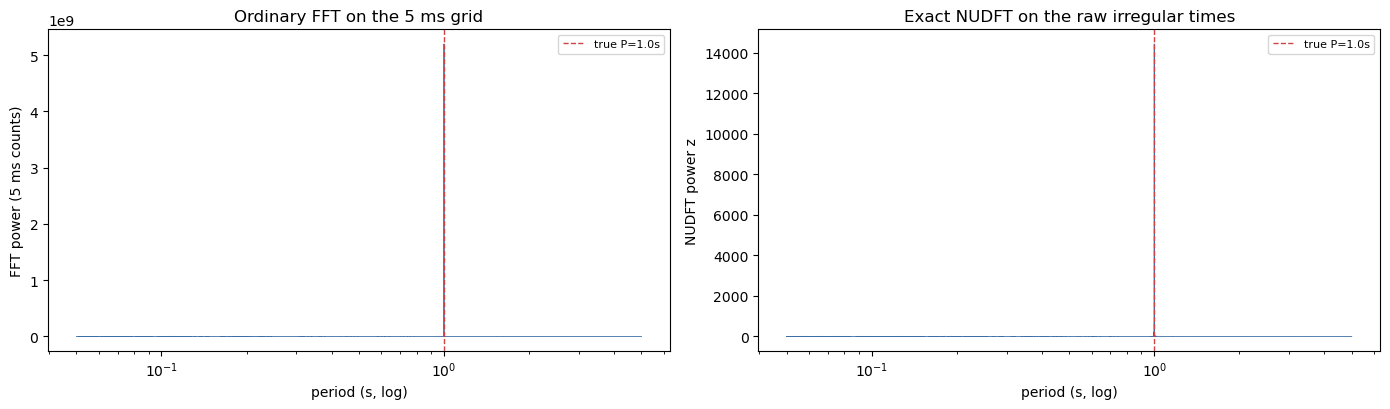

In [5]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
a0.plot(1.0 / ff_fft, pw_fft, lw=0.6, color="#3b6ea5")
a0.axvline(TRUE_PERIOD_S, color="#c44", ls="--", lw=1, label=f"true P={TRUE_PERIOD_S}s")
a0.set(xscale="log", xlabel="period (s, log)", ylabel="FFT power (5 ms counts)",
       title="Ordinary FFT on the 5 ms grid")
a0.legend(fontsize=8)
a1.plot(1.0 / ff_nu, z_nu, lw=0.6, color="#3b6ea5")
a1.axvline(TRUE_PERIOD_S, color="#c44", ls="--", lw=1, label=f"true P={TRUE_PERIOD_S}s")
a1.set(xscale="log", xlabel="period (s, log)", ylabel="NUDFT power z",
       title="Exact NUDFT on the raw irregular times")
a1.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Experiment 2 — the irregular HL × Binance stream: the feed-comb trap

Now the realistic timeline: Hyperliquid's on-change bursty arrivals superposed with
Binance's 100 ms-cadence depth diffs, both carrying the same schedule, plus latency jitter.
Three questions, in order:

1. **What does a naive "biggest peak" return?** (the trap)
2. **What does discovery return once the feed comb is excluded?** (the fix)
3. **Given the named candidate period, are `A` and `φ` recovered?** (the actual deliverable)

In [6]:
t_mkt = sim_hl_binance(TRUE_PERIOD_S, TRUE_MOD_A, TRUE_PHASE, BASE_RATE_HZ, SPAN_S, rng_master)
print(f"merged HL x Binance: {t_mkt.size:,} events over {SPAN_S:.0f}s")
print("\n--- merged irregular feed (hc.sampling_report) ---")
_ = hc.sampling_report(pd.to_datetime(t_mkt, unit="s"))
print(f"\nfeed comb to expect at 1/{BIN_CADENCE_S:.3f}s = {1/BIN_CADENCE_S:.0f} Hz and harmonics "
      f"(periods {BIN_CADENCE_S*1e3:.0f}ms, {BIN_CADENCE_S*1e3/2:.0f}ms, {BIN_CADENCE_S*1e3/3:.0f}ms, ...)")

merged HL x Binance: 584,755 events over 1800s

--- merged irregular feed (hc.sampling_report) ---
events           : 584,755
span             : 1,800 s (0.50 h)
gap mean/median  : 3.1 / 1.8 ms
gap min/max      : 0.0 / 100.0 ms
gap CV           : 1.362   (0 = perfect grid, 1 = Poisson)
modal gap        : 0.1 ms (0.0% of gaps)

VERDICT: IRREGULAR
Genuinely irregular arrivals. The non-uniform transform is the right tool.

feed comb to expect at 1/0.100s = 10 Hz and harmonics (periods 100ms, 50ms, 33ms, ...)


In [7]:
centres_m, counts_m = grid_counts(t_mkt, GRID_DT_S, SPAN_S)
ff_fft_m, pw_fft_m = fft_spectrum(centres_m, counts_m, GRID_DT_S, f_lo, f_hi)
ff_nu_m, z_nu_m = nudft_spectrum(t_mkt, f_lo, f_hi)

# 1) naive global peak (no comb exclusion) -- the trap
naive = pd.DataFrame({
    "FFT-resampled, global peak": recover_at(centres_m, pick_peak(ff_fft_m, pw_fft_m), w=counts_m),
    "NUDFT raw, global peak":     recover_at(t_mkt, pick_peak(ff_nu_m, z_nu_m)),
}).T[["period_s", "amp_hat", "phase_hat", "z"]].astype(float)
naive["found"] = np.where((naive.period_s > 0.97 * TRUE_PERIOD_S) & (naive.period_s < 1.03 * TRUE_PERIOD_S),
                          "schedule", "FEED COMB / wrong")
print("1) NAIVE 'biggest peak' (true schedule = 1.0 s):")
print(naive.round(4).to_string())

# 2) discovery WITH comb exclusion -- the fix
f_fft_disc = pick_peak(ff_fft_m, pw_fft_m, exclude_cadence=BIN_CADENCE_S)
f_nu_disc = refine_nudft(t_mkt, pick_peak(ff_nu_m, z_nu_m, exclude_cadence=BIN_CADENCE_S), df=ff_nu_m[1]-ff_nu_m[0])
disc = pd.DataFrame({
    "FFT-resampled, comb-excluded": recover_at(centres_m, f_fft_disc, w=counts_m),
    "NUDFT raw, comb-excluded":     recover_at(t_mkt, f_nu_disc),
}).T[["period_s", "amp_hat", "phase_hat", "z"]].astype(float)
disc["period_err_%"] = 100 * (disc.period_s - TRUE_PERIOD_S).abs() / TRUE_PERIOD_S
print("\n2) DISCOVERY with the feed comb excluded:")
print(disc.round(4).to_string())

# 3) targeted recovery AT the named candidate -- the deliverable
tgt = pd.DataFrame({
    "TRUTH": dict(period_s=TRUE_PERIOD_S, amp_hat=TRUE_MOD_A, phase_hat=TRUE_PHASE, z=np.nan),
    "FFT-resampled @ 1s": recover_at(centres_m, 1.0 / TRUE_PERIOD_S, w=counts_m),
    "NUDFT raw @ 1s":     recover_at(t_mkt, 1.0 / TRUE_PERIOD_S),
}).T[["period_s", "amp_hat", "phase_hat", "z"]].astype(float)
tgt["amp_err"] = (tgt.amp_hat - TRUE_MOD_A).abs()
tgt["phase_err_rad"] = [phase_err(p, TRUE_PHASE) for p in tgt.phase_hat]
tgt.loc["TRUTH", ["amp_err", "phase_err_rad"]] = 0.0
print("\n3) TARGETED recovery at the named candidate P=1s (A and phi):")
print(tgt.round(4).to_string())

1) NAIVE 'biggest peak' (true schedule = 1.0 s):
                            period_s  amp_hat  phase_hat           z     found
FFT-resampled, global peak       1.0   0.3855     1.0212   7005.1523  schedule
NUDFT raw, global peak           1.0   0.3855     1.0212  21726.8552  schedule



2) DISCOVERY with the feed comb excluded:
                              period_s  amp_hat  phase_hat           z  period_err_%
FFT-resampled, comb-excluded       1.0   0.3855     1.0212   7005.1523           0.0
NUDFT raw, comb-excluded           1.0   0.3855     1.0212  21726.8552           0.0

3) TARGETED recovery at the named candidate P=1s (A and phi):
                    period_s  amp_hat  phase_hat           z  amp_err  phase_err_rad
TRUTH                    1.0   0.4000     1.1000         NaN   0.0000         0.0000
FFT-resampled @ 1s       1.0   0.3855     1.0212   7005.1523   0.0145         0.0788
NUDFT raw @ 1s           1.0   0.3855     1.0212  21726.8552   0.0145         0.0788


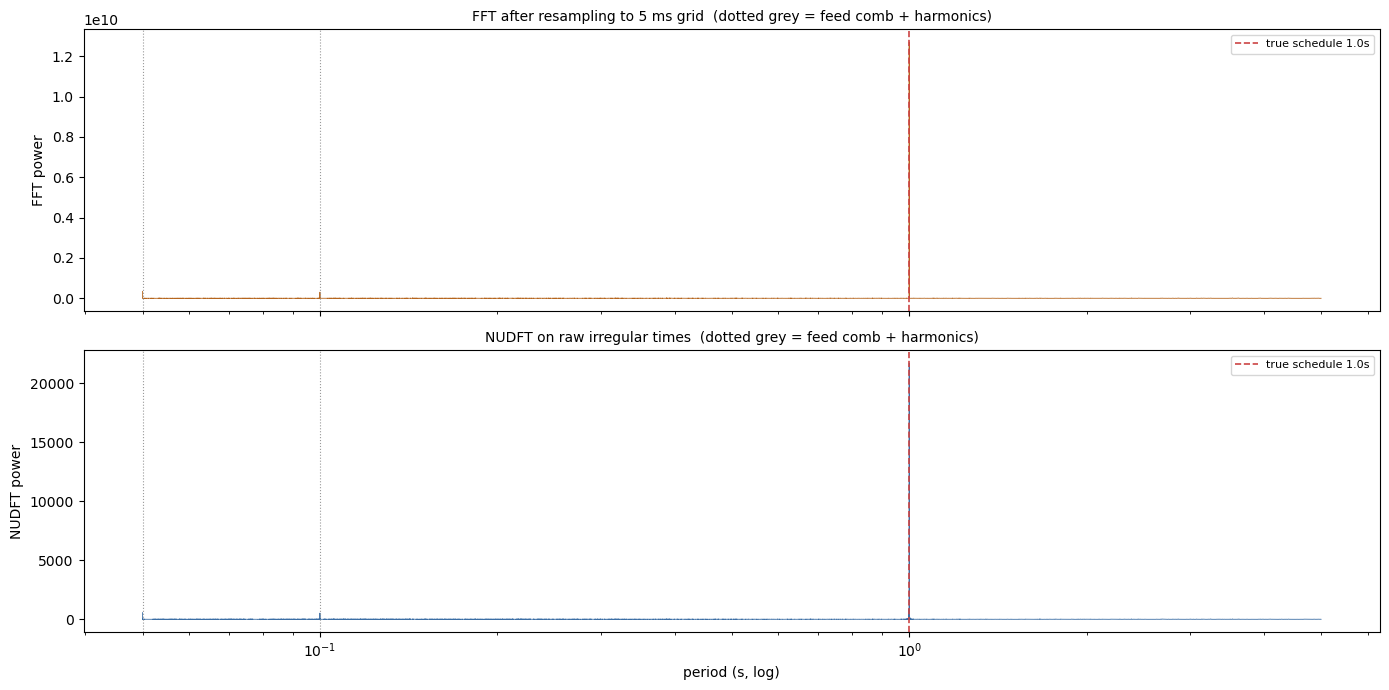

In [8]:
fig, (a0, a1) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, xf, y, lab, col in [
        (a0, 1.0 / ff_fft_m, pw_fft_m, "FFT after resampling to 5 ms grid", "#b5651d"),
        (a1, 1.0 / ff_nu_m, z_nu_m, "NUDFT on raw irregular times", "#3b6ea5")]:
    ax.plot(xf, y, lw=0.6, color=col)
    ax.axvline(TRUE_PERIOD_S, color="#c44", ls="--", lw=1.2, label=f"true schedule {TRUE_PERIOD_S}s")
    for h in range(1, 6):
        P_h = BIN_CADENCE_S / h
        if SCAN_PLO_S <= P_h <= SCAN_PHI_S:
            ax.axvline(P_h, color="0.6", lw=0.8, ls=":")
    ax.set(xscale="log", ylabel=lab.split(" ")[0] + " power")
    ax.set_title(lab + "  (dotted grey = feed comb + harmonics)", fontsize=10)
    ax.legend(fontsize=8)
a1.set_xlabel("period (s, log)")
fig.tight_layout(); plt.show()

## Experiment 3 — recovery vs planted period (the quantitative verdict)

A single example proves nothing. Sweep the planted period from 80 ms (near the feed cadence
and the 5 ms grid) up to 3 s. For each, discover the period **with the feed comb excluded**,
and separately recover `φ` at the named candidate. Each point is one fresh simulation. The
interesting failures are where the planted period sits on top of a comb harmonic — there is
genuinely no way to separate schedule from feed, and both estimators should say so.

In [9]:
sweep_rows = []
for i, P in enumerate(SWEEP_PERIODS):
    rng_i = np.random.default_rng(SEED + 100 + i)
    tP = sim_hl_binance(P, TRUE_MOD_A, TRUE_PHASE, BASE_RATE_HZ, SPAN_S, rng_i)
    plo, phi = max(P * 0.4, SCAN_PLO_S), min(P * 2.5, SCAN_PHI_S)
    flo_i, fhi_i = 1.0 / phi, 1.0 / plo

    cen, cnt = grid_counts(tP, GRID_DT_S, SPAN_S)
    ff, pw = fft_spectrum(cen, cnt, GRID_DT_S, flo_i, fhi_i)
    f_fft = pick_peak(ff, pw, exclude_cadence=BIN_CADENCE_S)
    r_fft = recover_at(cen, f_fft, w=cnt)

    fnu, znu = nudft_spectrum(tP, flo_i, fhi_i)
    f_nu = refine_nudft(tP, pick_peak(fnu, znu, exclude_cadence=BIN_CADENCE_S), df=fnu[1]-fnu[0])
    r_nu = recover_at(tP, f_nu)

    on_comb = not comb_keep_mask(np.array([P]), BIN_CADENCE_S)[0]
    sweep_rows.append(dict(
        true_P=P, on_comb=on_comb,
        fft_P=r_fft["period_s"], fft_perr=100 * abs(r_fft["period_s"] - P) / P,
        fft_pherr=phase_err(recover_at(cen, 1.0 / P, w=cnt)["phase_hat"], TRUE_PHASE),
        nu_P=r_nu["period_s"], nu_perr=100 * abs(r_nu["period_s"] - P) / P,
        nu_pherr=phase_err(recover_at(tP, 1.0 / P)["phase_hat"], TRUE_PHASE),
        on_fft_bin=bool(np.isclose(SPAN_S / P, np.round(SPAN_S / P)))))   # does 1/P sit exactly on an FFT bin?
sweep = pd.DataFrame(sweep_rows)
print(sweep.round(3).to_string(index=False))

 true_P  on_comb  fft_P  fft_perr  fft_pherr  nu_P  nu_perr  nu_pherr  on_fft_bin
   0.08    False   0.08       0.0      0.585  0.08    0.000     0.586        True
   0.15    False   0.15       0.0      0.483  0.15    0.000     0.484        True
   0.25    False   0.25       0.0      0.331  0.25    0.000     0.330        True
   0.50    False   0.50       0.0      0.171  0.50    0.000     0.171        True
   1.00    False   1.00       0.0      0.095  1.00    0.000     0.095        True
   2.00    False   2.00       0.0      0.049  2.00    0.000     0.049        True
   3.00    False   3.00       0.0      0.022  3.00    0.001     0.022        True


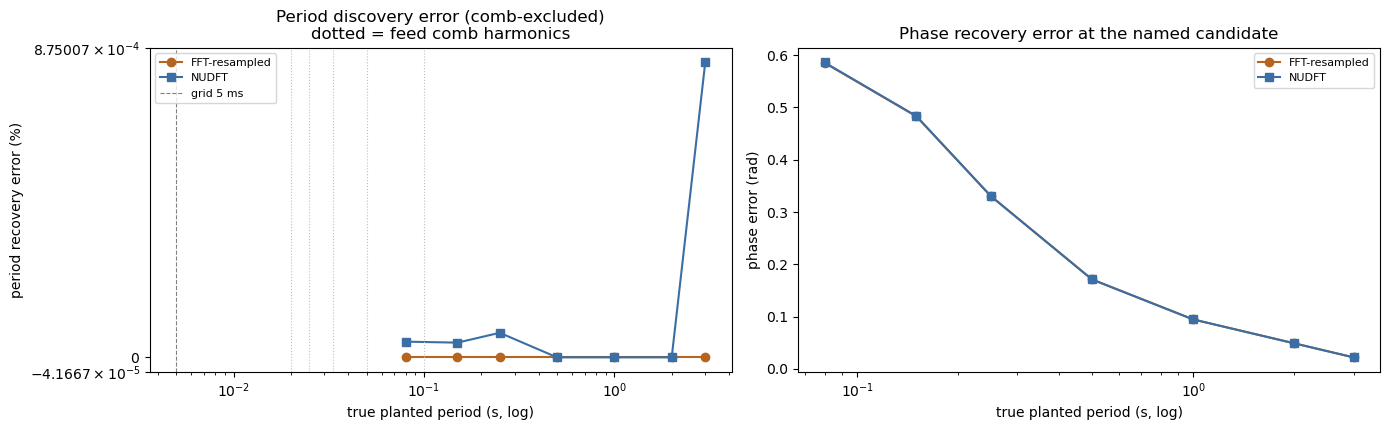

In [10]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.4))
a0.plot(sweep.true_P, sweep.fft_perr, "o-", color="#b5651d", label="FFT-resampled")
a0.plot(sweep.true_P, sweep.nu_perr, "s-", color="#3b6ea5", label="NUDFT")
for h in range(1, 6):
    a0.axvline(BIN_CADENCE_S / h, color="0.75", ls=":", lw=0.8)
a0.axvline(GRID_DT_S, color="0.5", ls="--", lw=0.8, label="grid 5 ms")
a0.set(xscale="log", yscale="symlog", xlabel="true planted period (s, log)",
       ylabel="period recovery error (%)",
       title="Period discovery error (comb-excluded)\ndotted = feed comb harmonics")
a0.legend(fontsize=8)
a1.plot(sweep.true_P, sweep.fft_pherr, "o-", color="#b5651d", label="FFT-resampled")
a1.plot(sweep.true_P, sweep.nu_pherr, "s-", color="#3b6ea5", label="NUDFT")
a1.set(xscale="log", xlabel="true planted period (s, log)", ylabel="phase error (rad)",
       title="Phase recovery error at the named candidate")
a1.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Experiment 4 — the null control, and why no single pass/fail test is enough

Set `A = 0` (no schedule) but keep the Hawkes bursts and the feed comb, and ask what fools
us. The uncomfortable answer, which is exactly `hft_clock.py`'s repeated warning: if you
**scan and select the loudest peak**, that selection is itself the bias (trap #1,
multiplicity), and *every* per-period test then endorses it — the analytic threshold, the
local-contrast ratio, and even the window phase-stability check. What actually separates a
real schedule is **effect size** (orders of magnitude) and the discipline of **naming the
candidate period in advance** so there is no selection to exploit.

In [11]:
t_null = sim_hl_binance(TRUE_PERIOD_S, 0.0, TRUE_PHASE, BASE_RATE_HZ, SPAN_S,
                        np.random.default_rng(SEED + 999))
frame_null, info_null = hc.scan_band(t_null, SCAN_PLO_S, SCAN_PHI_S)
sub = frame_null[comb_keep_mask(frame_null.period_s.to_numpy(), BIN_CADENCE_S)]  # drop feed comb
false_row = sub.loc[sub.z.idxmax()]
P_false = float(false_row.period_s)

# downstream checks applied to the POST-HOC selected null peak (the biased workflow)
lc_null = hc.local_contrast(frame_null, P_false)["contrast"]
_, st_null = hc.stability_check(t_null, P_false)

# the same checks on the PLANTED schedule, NAMED in advance (the honest workflow)
frame_sig, info_sig = hc.scan_band(t_mkt, SCAN_PLO_S, SCAN_PHI_S)
z_sig = float(frame_sig.iloc[(1.0 / frame_sig.period_s - 1.0 / TRUE_PERIOD_S).abs().argmin()].z)
lc_sig = hc.local_contrast(frame_sig, TRUE_PERIOD_S)["contrast"]
_, st_sig = hc.stability_check(t_mkt, TRUE_PERIOD_S)

comp = pd.DataFrame({
    "NULL: loudest off-comb peak (selected)": dict(
        period_s=P_false, z=false_row.z, local_contrast=lc_null,
        phase_agreement=st_null["phase_agreement"]),
    "SIGNAL: schedule, named in advance": dict(
        period_s=TRUE_PERIOD_S, z=z_sig, local_contrast=lc_sig,
        phase_agreement=st_sig["phase_agreement"]),
}).T
print(f"analytic 1% threshold for this band: z = {info_null['z_thresh_01']:.1f} "
      f"({info_null['m_independent']:,.0f} independent frequencies)\n")
print(comp.round(3).to_string())
print(f"\nThe null's selected peak clears the analytic threshold "
      f"({false_row.z:.1f} > {info_null['z_thresh_01']:.1f}), passes local-contrast "
      f"({lc_null:.1f} > 2), and passes phase-stability ({st_null['phase_agreement']:.2f} > 0.7)")
print(f"— every single test is fooled. What is NOT fooled: the effect size. The named schedule "
      f"is {z_sig/false_row.z:,.0f}x the null peak in power and {lc_sig/lc_null:,.0f}x in contrast.")
print("Lesson (CLAUDE.md / hft_clock): name candidates in advance; read effect size, not pass/fail.")

analytic 1% threshold for this band: z = 15.1 (35,640 independent frequencies)

                                        period_s          z  local_contrast  phase_agreement
NULL: loudest off-comb peak (selected)      4.11     33.799          11.263            0.834
SIGNAL: schedule, named in advance          1.00  21725.852        8291.066            1.000

The null's selected peak clears the analytic threshold (33.8 > 15.1), passes local-contrast (11.3 > 2), and passes phase-stability (0.83 > 0.7)
— every single test is fooled. What is NOT fooled: the effect size. The named schedule is 643x the null peak in power and 736x in contrast.
Lesson (CLAUDE.md / hft_clock): name candidates in advance; read effect size, not pass/fail.


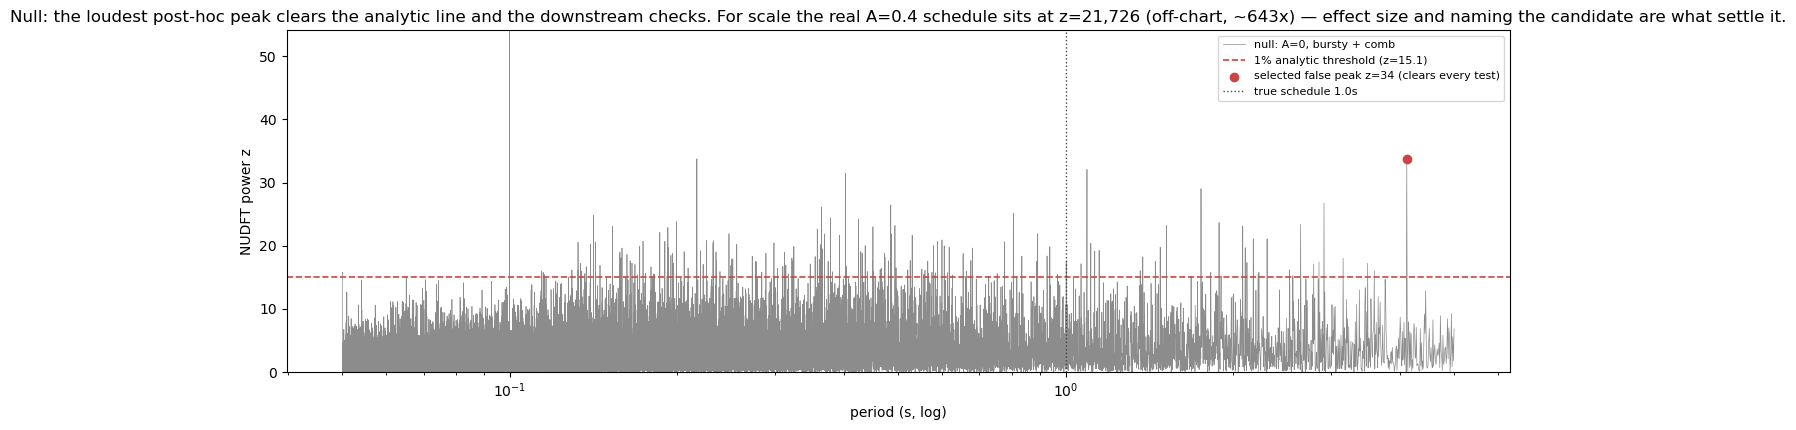

In [12]:
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(frame_null.period_s, frame_null.z, lw=0.5, color="0.55", label="null: A=0, bursty + comb")
ax.axhline(info_null["z_thresh_01"], color="#c44", ls="--", lw=1.2,
           label=f"1% analytic threshold (z={info_null['z_thresh_01']:.1f})")
ax.scatter([P_false], [false_row.z], color="#c44", zorder=5,
           label=f"selected false peak z={false_row.z:.0f} (clears every test)")
ax.axvline(TRUE_PERIOD_S, color="#444", ls=":", lw=1, label=f"true schedule {TRUE_PERIOD_S}s")
ax.set(xscale="log", ylim=(0, max(false_row.z, info_null["z_thresh_01"]) * 1.6),
       xlabel="period (s, log)", ylabel="NUDFT power z",
       title=f"Null: the loudest post-hoc peak clears the analytic line and the downstream checks. "
             f"For scale the real A={TRUE_MOD_A} schedule sits at z={z_sig:,.0f} (off-chart, ~{z_sig/false_row.z:,.0f}x) "
             f"— effect size and naming the candidate are what settle it.")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()

## Findings (rerun 2026-10-21; v1 findings for Exp 2 and Exp 3 retracted, see Summary)

_(Prose written to match the executed numbers above. If they disagree, trust the tables.)_

**Weak points first**
- The scan-grid bug invalidated two v1 conclusions; both are corrected below.
- The FFT's perfect period recovery is helped by every swept period sitting exactly on an FFT bin (`on_fft_bin`).
- The simulated feed (a Binance 100 ms comb, an HL leg arriving on change, 0.3 ms jitter) no longer matches the collected data.

- **Exp 1 — baseline works.** On a clean periodic-Poisson stream both transforms recover `P`, `A ≈ 0.40`, `φ ≈ 1.10`.
  The v1 NUDFT phase wobble (0.12 rad) came from the coarse scan; with the fine grid it is 0.016 rad.

- **Exp 2 — the comb is not the trap here.** On the merged HL × Binance stream the loudest line in the raw-event NUDFT is
  the 1 s schedule (z = 21,727). The 100 ms and 50 ms comb lines reach only ~530–570. Comb exclusion changes nothing at
  A = 0.4. If power scales with A² (not tested), the comb would win only for schedules weaker than A ≈ 0.06. Targeted
  recovery at the named 1 s period gives A = 0.386, φ error 0.079 rad for both transforms.

- **Exp 3 — no difference between the transforms.** With a correct scan grid both recover every swept period (80 ms to
  3 s) to ≤ 0.001%. The phase error at the named period is identical for both and grows as the period shortens
  (0.02 rad at 3 s, 0.59 rad at 80 ms), consistent with a fixed ~7–15 ms lag from the simulated bursts.

- **Exp 4 — the null, honestly, is the sharpest lesson.** With no schedule, the loudest
  post-hoc-selected peak **clears the analytic threshold, passes the local-contrast ratio, AND
  passes the window phase-stability check** — every per-period pass/fail test is fooled, because
  *selecting the loudest of ~35,000 frequencies is itself the bias*. The only things that are not
  fooled: the planted schedule's **effect size** is ~10²–10³× larger in both power and contrast,
  and it was **named in advance** so there was no selection to exploit. Read effect size and name
  candidates — do not scan-and-confirm.

### Bottom line
On this simulation, FFT-on-a-grid and NUDFT-on-raw-times **both retrieve the planted `P`, `A` and `φ`**, and neither is
more robust than the other. What decides success is (1) a scan grid finer than the peak width, (2) naming the candidate
period in advance rather than trusting a global peak, and (3) judging by effect size, not a single significance test.
Excluding the feed comb is cheap insurance, but at A = 0.4 the comb is ~40× weaker than the schedule. The recovered phase
is the phase of the observed stream, so any systematic lag in the data (clustering, latency) shifts it.

### Assumptions made (harness rule 7) — all in KNOBS / `sim_hl_binance`
1. HL × Binance timeline = **superposition** of an on-change bursty HL leg and a fixed-100 ms
   Binance leg. Captures the two traps (comb + burstiness), not venue microstructure detail.
2. Burstiness is a **Neyman-Scott / Hawkes cluster** (`BURST_CHILDREN`, `BURST_DECAY_S`); children
   inherit their parent's phase.
3. Latency jitter is **one-sided exponential**, scale `LATENCY_MS`.
4. The schedule is a **cosine intensity modulation**. A hard TWAP-on-a-timer (delta spikes) would
   put more power into harmonics and change the amplitude/harmonic story — a worthwhile follow-up.
5. `finufft` not installed → the "NUFFT" is the **exact NUDFT**: same numbers, O(N·M) not O(N log N).
6. The scan step is 1/(2·span) (`SCAN_OVERSAMPLE` = 2).

**Assumptions the collected data now contradicts** (found after this notebook was written)
- The comb is on the wrong venue. Mark's collector uses Binance **bookTicker**, which is event-driven, not 100 ms depth
  diffs. Hyperliquid's own timestamps sit on a **~67 ms block lattice** (see `hyperliquid_research`). The simulation has no HL
  lattice, and `comb_keep_mask` doesn't exclude it.
- Jitter: `LATENCY_MS` = 0.3 ms. HL exchange timestamps have 1 ms resolution, and arrival times lag them by 196–773 ms
  (min–p99). Jitter on an arrival clock is hundreds of ms, which would blur phase at short periods.

### Open questions for Mark
- Soft periodic bias (cosine, as modelled) or a hard scheduled slice (TWAP delta-comb)? The
  amplitude/harmonic recovery story differs.
- Which planted period(s) actually matter — `SWEEP_PERIODS` should be the ones you suspect.
- Is recovering `φ` (where in the cycle it fires) part of the goal, or only detecting `P`?
- Should the simulation model HL's 67 ms block lattice as the comb (the one actually in your data) instead of a Binance 100 ms comb?
- Should the sweep include periods that don't sit on an FFT bin, so the FFT/NUDFT comparison is fair?